# Olist E-Commerce Performance Analysis (SQL)

**Author:** Daljeet Kaur
**Tools:** SQL (SQLite — CTEs, window functions), Python (pandas, matplotlib)
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) — ~100K orders, 9 relational tables, Sep 2016 – Oct 2018. Amounts are in Brazilian reais (R$).

## Objective
Olist is a marketplace that connects small Brazilian sellers to large online stores. Leadership wants to know:

1. How fast is revenue growing, and is order value holding up?
2. Which product categories drive revenue?
3. Do customers come back?
4. Does late delivery hurt customer satisfaction — and by how much?
5. Which regions have delivery problems?
6. How dependent is the marketplace on its biggest sellers?

All business logic lives in [`sql/queries.sql`](../sql/queries.sql). Python is only used to load the data, run the SQL and chart the results.

In [1]:
import glob, os, re, sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"

DATA_DIR, IMG_DIR, RESULTS_DIR = "../data", "../images", "../results"

Matplotlib is building the font cache; this may take a moment.


## 1. Build the database
Each CSV becomes a table in an in-memory SQLite database (`olist_orders_dataset.csv` → `orders`).

In [2]:
def build_database(data_dir=DATA_DIR):
    con = sqlite3.connect(":memory:")
    for path in sorted(glob.glob(f"{data_dir}/*.csv")):
        table = (os.path.basename(path).replace("olist_", "")
                 .replace("_dataset.csv", "").replace(".csv", ""))
        df = pd.read_csv(path)
        df.to_sql(table, con, index=False)
        print(f"{table:<36} {len(df):>8,} rows  {df.shape[1]:>2} cols")
    return con

con = build_database()

customers                              99,441 rows   5 cols
order_items                           112,650 rows   7 cols
order_payments                        103,886 rows   5 cols
order_reviews                         100,000 rows   7 cols
orders                                 99,441 rows   8 cols
products                               32,951 rows   9 cols
sellers                                 3,095 rows   4 cols
product_category_name_translation          71 rows   2 cols


Load the named queries from the SQL file so the notebook and the `.sql` file never drift apart.

In [3]:
def load_queries(path="../sql/queries.sql"):
    text = open(path).read()
    blocks = re.split(r"^-- name: ", text, flags=re.M)[1:]
    return {b.split("\n", 1)[0].strip(): b.split("\n", 1)[1] for b in blocks}

Q = load_queries()
run = lambda name: pd.read_sql(Q[name], con)
print(list(Q))

['data_quality_overview', 'monthly_revenue_growth', 'top_categories', 'customer_repeat_rate', 'delivery_vs_reviews', 'state_performance', 'seller_concentration', 'payment_mix']


## 2. Data quality check

In [4]:
dq = run("data_quality_overview")
dq

,total_orders,delivered_orders,pct_delivered,canceled_orders,first_order,last_order,delivered_missing_date
0,99441,96478,97.0,625,2016-09-04,2018-10-17,8


97% of orders were delivered. Only 8 delivered orders are missing a delivery date, so they are simply excluded from delivery-time metrics. Sep 2016 – Dec 2016 and Sep – Oct 2018 have very few orders (system launch and data cut-off), so trend analysis uses **Jan 2017 – Aug 2018**.

## 3. Revenue growth (LAG window function)

In [5]:
monthly = run("monthly_revenue_growth")
monthly

,month,orders,revenue,avg_order_value,revenue_mom_pct,cumulative_revenue
0,2017-01,750,127482.37,169.98,NaN,127482.37
1,2017-02,1653,271239.32,164.09,112.8,398721.69
2,2017-03,2546,414330.95,162.74,52.8,813052.64
3,2017-04,2303,390812.40,169.70,-5.7,1203865.04
4,2017-05,3546,566851.40,159.86,45.0,1770716.44
5,2017-06,3135,490050.37,156.32,-13.5,2260766.81
6,2017-07,3872,566299.08,146.25,15.6,2827065.89
7,2017-08,4193,645832.36,154.03,14.0,3472898.25
8,2017-09,4150,701077.49,168.93,8.6,4173975.74
9,2017-10,4478,751117.01,167.73,7.1,4925092.75


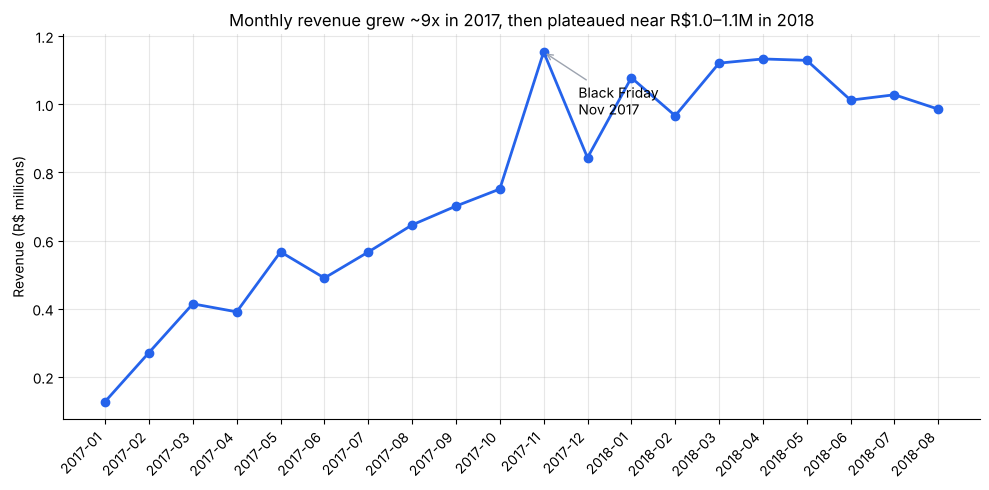

In [6]:
fig, ax1 = plt.subplots()
ax1.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color=BLUE, lw=2)
ax1.set_ylabel("Revenue (R$ millions)")
ax1.set_title("Monthly revenue grew ~9x in 2017, then plateaued near R$1.0–1.1M in 2018")
peak = monthly.loc[monthly["revenue"].idxmax()]
ax1.annotate("Black Friday\nNov 2017", (peak["month"], peak["revenue"] / 1e6),
             xytext=(25, -45), textcoords="offset points",
             arrowprops=dict(arrowstyle="->", color=GREY))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_monthly_revenue.png", dpi=150)

In [7]:
first, last = monthly.iloc[0], monthly.iloc[-1]
h1_2017 = monthly[monthly.month.between("2017-01", "2017-06")].revenue.sum()
h1_2018 = monthly[monthly.month.between("2018-01", "2018-06")].revenue.sum()
print(f"Total revenue Jan 2017 – Aug 2018: R${monthly.revenue.sum():,.0f}")
print(f"H1 2018 vs H1 2017 revenue: {100 * (h1_2018 / h1_2017 - 1):+.0f}%")
print(f"Average order value range: R${monthly.avg_order_value.min():.0f} – R${monthly.avg_order_value.max():.0f}")

Total revenue Jan 2017 – Aug 2018: R$15,373,120
H1 2018 vs H1 2017 revenue: +185%
Average order value range: R$146 – R$170


**Finding:** Revenue grew ~9x from Jan 2017 to its Nov 2017 Black Friday peak, and H1 2018 revenue was 2.85x H1 2017 (+185%). Growth then flattened in 2018 (monthly MoM between −10% and +16%). Average order value stayed steady at R$146–170, so growth came from **more orders, not bigger baskets**.

## 4. Top product categories (RANK + running share)

In [6]:
cats = run("top_categories")
cats

,rank,category,orders,revenue,avg_item_price,pct_of_revenue,cumulative_pct
0,1,health_beauty,8647,1233132.0,130.28,9.3,9.3
1,2,watches_gifts,5495,1166177.0,199.04,8.8,18.1
2,3,bed_bath_table,9272,1023435.0,93.44,7.7,25.9
3,4,sports_leisure,7530,954853.0,113.25,7.2,33.1
4,5,computers_accessories,6530,888725.0,116.26,6.7,39.8
5,6,furniture_decor,6307,711928.0,87.25,5.4,45.2
6,7,housewares,5743,615629.0,90.60,4.7,49.9
7,8,cool_stuff,3559,610204.0,164.12,4.6,54.5
8,9,auto,3810,578967.0,139.85,4.4,58.9
9,10,toys,3804,471286.0,116.94,3.6,62.4


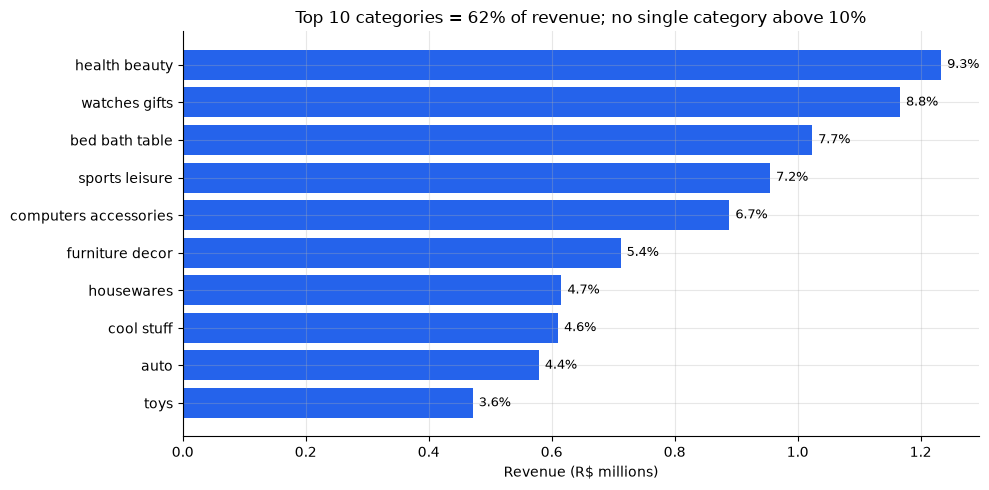

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
c = cats.sort_values("revenue")
ax.barh(c["category"].str.replace("_", " "), c["revenue"] / 1e6, color=BLUE)
for y, (v, p) in enumerate(zip(c["revenue"] / 1e6, c["pct_of_revenue"])):
    ax.text(v + 0.01, y, f"{p}%", va="center", fontsize=9)
ax.set_xlabel("Revenue (R$ millions)")
ax.set_title("Top 10 categories = 62% of revenue; no single category above 10%")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_top_categories.png", dpi=150)

**Finding:** Revenue is well diversified — health & beauty leads at 9.3%, and it takes 10 categories to reach 62%. *Watches & gifts* is #2 by revenue on ~40% fewer orders than *bed, bath & table* because its average item price (R$199) is more than double — a good target for premium promotions.

## 5. Customer retention

In [8]:
repeat = run("customer_repeat_rate")
repeat

,customers,repeat_customers,repeat_rate_pct,avg_orders_per_customer,max_orders_one_customer
0,93358,2801,3.0,1.033,15


**Finding:** Only **3.0%** of 93K unique customers ever placed a second order. Almost all revenue comes from first-time buyers, which makes growth expensive. A post-purchase win-back campaign (e.g. a discount on the second order) is the biggest untapped lever.

## 6. Late delivery vs. customer reviews (ROW_NUMBER, CASE buckets)

In [9]:
deliv = run("delivery_vs_reviews")
deliv

,delivery_bucket,orders,pct_of_orders,avg_days_to_deliver,avg_review_score,pct_one_star
0,1. On time / early,88644,91.9,10.9,4.28,6.8
1,2. Late 1-3 days,2662,2.8,21.1,3.75,14.2
2,3. Late 4-7 days,1819,1.9,26.7,2.30,53.7
3,4. Late 8+ days,3345,3.5,42.5,1.72,68.9


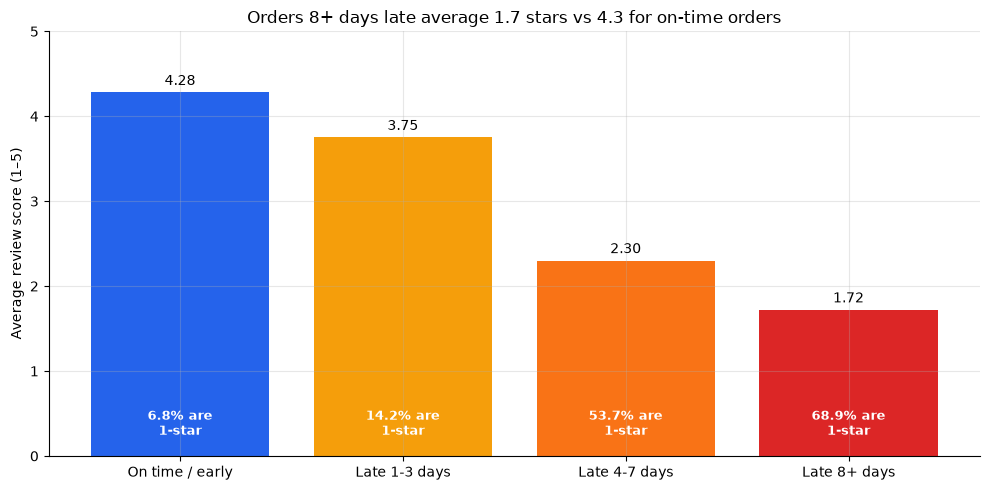

In [10]:
fig, ax1 = plt.subplots(figsize=(10, 5))
labels = deliv["delivery_bucket"].str[3:]
colors = [BLUE, "#f59e0b", "#f97316", RED]
bars = ax1.bar(labels, deliv["avg_review_score"], color=colors)
ax1.bar_label(bars, fmt="%.2f", padding=3)
ax1.set_ylim(0, 5)
ax1.set_ylabel("Average review score (1–5)")
for i, p in enumerate(deliv["pct_one_star"]):
    ax1.text(i, 0.25, f"{p}% are\n1-star", ha="center", color="white", fontsize=9, fontweight="bold")
ax1.set_title("Orders 8+ days late average 1.7 stars vs 4.3 for on-time orders")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_delivery_vs_reviews.png", dpi=150)

In [13]:
late_share = deliv.loc[deliv.delivery_bucket != "1. On time / early", "pct_of_orders"].sum()
print(f"Orders delivered after the promised date: {late_share:.1f}%")

Orders delivered after the promised date: 8.2%


**Finding:** Delivery is the strongest driver of satisfaction in the data. About **8% of orders arrive late**. Orders 4–7 days late average 2.3 stars, and 8+ days late average **1.72 stars, with 69% one-star reviews** (vs 6.8% one-star for on-time orders). Fixing late deliveries protects ratings, which drive marketplace ranking and conversion.

## 7. Regional delivery performance

In [11]:
states = run("state_performance")
states

,state,orders,revenue,freight_pct_of_price,avg_days_to_deliver,late_pct
0,SP,40494,5768518.0,25.1,8.8,5.9
1,RJ,12350,2055402.0,31.6,15.3,13.5
2,MG,11354,1818892.0,31.6,12.0,5.6
3,RS,5344,861279.0,33.9,15.3,7.1
4,PR,4923,781709.0,33.5,12.0,5.0
5,SC,3546,595128.0,33.0,15.0,9.8
6,BA,3256,591138.0,38.5,19.3,14.0
7,DF,2080,346123.0,33.4,13.0,7.1
8,GO,1957,334212.0,34.2,15.6,8.2
9,ES,1995,317658.0,34.6,15.8,12.2


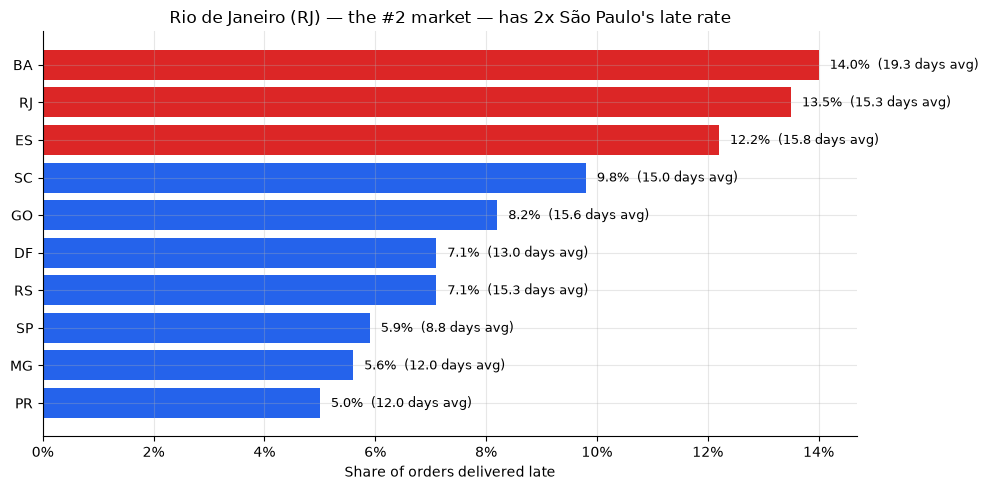

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
s = states.sort_values("late_pct")
colors = [RED if v >= 12 else BLUE for v in s["late_pct"]]
ax.barh(s["state"], s["late_pct"], color=colors)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for y, (v, d) in enumerate(zip(s["late_pct"], s["avg_days_to_deliver"])):
    ax.text(v + 0.2, y, f"{v}%  ({d} days avg)", va="center", fontsize=9)
ax.set_xlabel("Share of orders delivered late")
ax.set_title("Rio de Janeiro (RJ) — the #2 market — has 2x São Paulo's late rate")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_state_late_rate.png", dpi=150)

**Finding:** São Paulo (SP) is 41% of orders and is served fast (8.8 days, 5.9% late). **Rio de Janeiro (RJ)**, the second-largest market with R$2.1M revenue, has a **13.5% late rate** and 15.3-day average delivery. Bahia (BA, 14.0%) and Espírito Santo (ES, 12.2%) are also above 12%. A carrier review for RJ would protect the largest at-risk revenue pool.

## 8. Seller concentration (NTILE deciles)

In [13]:
sellers = run("seller_concentration")
sellers

,decile,sellers,revenue,pct_of_revenue
0,1,297,8873076.0,67.1
1,2,297,2006583.0,15.2
2,3,297,1026473.0,7.8
3,4,297,549968.0,4.2
4,5,297,328102.0,2.5
5,6,297,202659.0,1.5
6,7,297,117832.0,0.9
7,8,297,67111.0,0.5
8,9,297,36306.0,0.3
9,10,297,13387.0,0.1


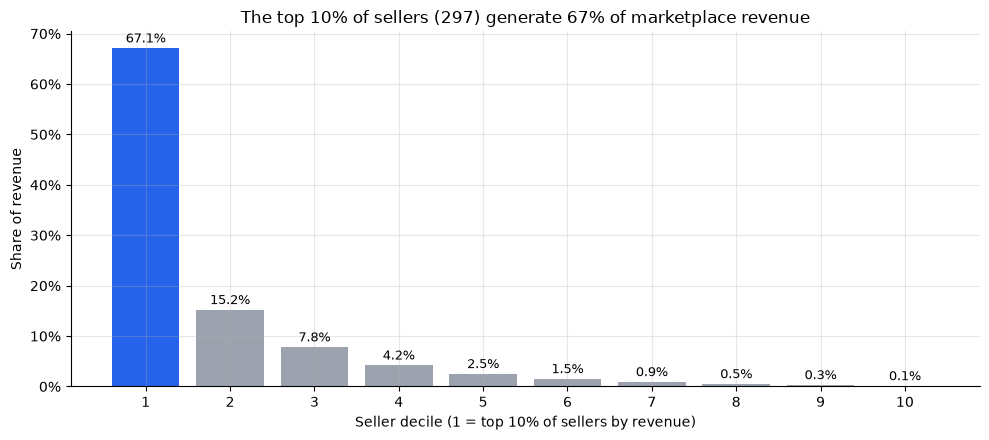

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(sellers["decile"].astype(str), sellers["pct_of_revenue"],
              color=[BLUE] + [GREY] * 9)
ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=9)
ax.set_xlabel("Seller decile (1 = top 10% of sellers by revenue)")
ax.set_ylabel("Share of revenue")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("The top 10% of sellers (297) generate 67% of marketplace revenue")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/05_seller_concentration.png", dpi=150)

**Finding:** Revenue is highly concentrated: 297 sellers (top decile) produce **67%** of revenue, and the bottom half of sellers produce under 6%. These top sellers need a dedicated account-management program — losing a few of them would hurt far more than losing a category.

## 9. Payment mix

In [15]:
pay = run("payment_mix")
pay

,payment_type,orders,pct_of_orders,avg_payment,avg_installments
0,credit_card,76505,76.9,163.32,3.5
1,boleto,19784,19.9,145.03,1.0
2,voucher,3866,3.9,65.70,1.0
3,debit_card,1528,1.5,142.57,1.0


Credit cards pay for 77% of orders, averaging 3.5 installments — buyers rely on installment plans, so interest-free installment promotions are a relevant marketing tool.

## 10. Save results

In [16]:
outputs = {"monthly_revenue_growth": monthly, "top_categories": cats,
           "customer_repeat_rate": repeat, "delivery_vs_reviews": deliv,
           "state_performance": states, "seller_concentration": sellers, "payment_mix": pay}
for name, df in outputs.items():
    df.to_csv(f"{RESULTS_DIR}/{name}.csv", index=False)
print("Saved:", ", ".join(f"{n}.csv" for n in outputs))

Saved: monthly_revenue_growth.csv, top_categories.csv, customer_repeat_rate.csv, delivery_vs_reviews.csv, state_performance.csv, seller_concentration.csv, payment_mix.csv


## Recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | Set carrier SLAs and proactive "your order is delayed" messaging, starting with RJ, BA and ES | 8+ days late → 1.72 avg stars, 69% one-star; RJ late rate 13.5% vs SP 5.9% |
| 2 | Launch a second-purchase campaign (post-delivery coupon, email/SMS) | Only 3.0% of customers ever reorder |
| 3 | Create a key-account program for the top 10% of sellers | 297 sellers = 67% of revenue |
| 4 | Promote high-ticket categories (watches & gifts, cool stuff) with installment offers | Watches & gifts is #2 by revenue at R$199 avg price; 77% of orders use credit-card installments |
| 5 | Re-plan growth targets: 2018 is flat, so growth must come from retention and new categories, not the 2017 launch curve | Monthly revenue flat at ~R$1.0–1.1M through 2018 |